In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import learning_curve

import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("../data/raw/student-por.csv", sep=";")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [4]:
ml_data = df.copy()

# Remove previous grades to predict final grade without G1 and G2
ml_data = ml_data.drop(columns=["G1", "G2"])

X = ml_data.drop(columns=["G3"])
y = ml_data["G3"]

# Convert categorical features into numerical features
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features:", X.shape)
print("Target:", y.shape)

Features: (649, 39)
Target: (649,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (519, 39)
Testing: (130, 39)


In [6]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

mae_scores = -cv_scores

print("Individual CV scores:", mae_scores)
print("Average CV MAE:", mae_scores.mean())

Individual CV scores: [1.99424241 2.00048801 2.16898561 2.02078576 1.85564358]
Average CV MAE: 2.008029075122038


In [7]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters: {'max_depth': 15, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 300}
Best CV MAE: 1.9881288295602684


In [8]:
best_model = grid_search.best_estimator_

print("Optimized Random Forest model:")
print(best_model)

Optimized Random Forest model:
RandomForestRegressor(max_depth=15, min_samples_leaf=4, min_samples_split=10,
                      n_estimators=300, random_state=42)


In [9]:
predictions = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Grade": y_test.values,
    "Predicted Grade": predictions
})

comparison.head(15)

,Actual Grade,Predicted Grade
0,19,12.260498
1,12,12.698518
2,18,13.811938
3,11,12.003540
4,11,12.024227
5,17,13.061143
6,18,14.555286
7,8,8.845539
8,10,12.118584
9,11,12.204327


In [10]:
mae = mean_absolute_error(y_test, predictions)

mse = mean_squared_error(y_test, predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, predictions)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 2.034372625575269
MSE: 7.694126294039286
RMSE: 2.7738288148404697
R2 Score: 0.2109977041257255


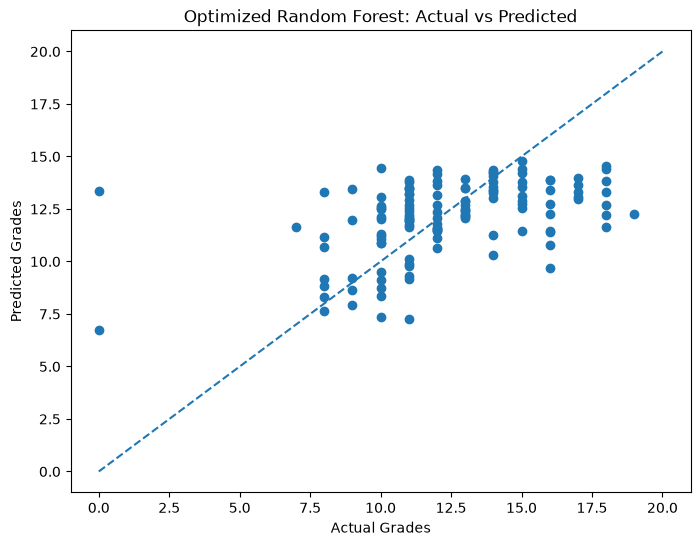

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions)

plt.plot([0, 20], [0, 20], linestyle="--")

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")

plt.title("Optimized Random Forest: Actual vs Predicted")

plt.show()

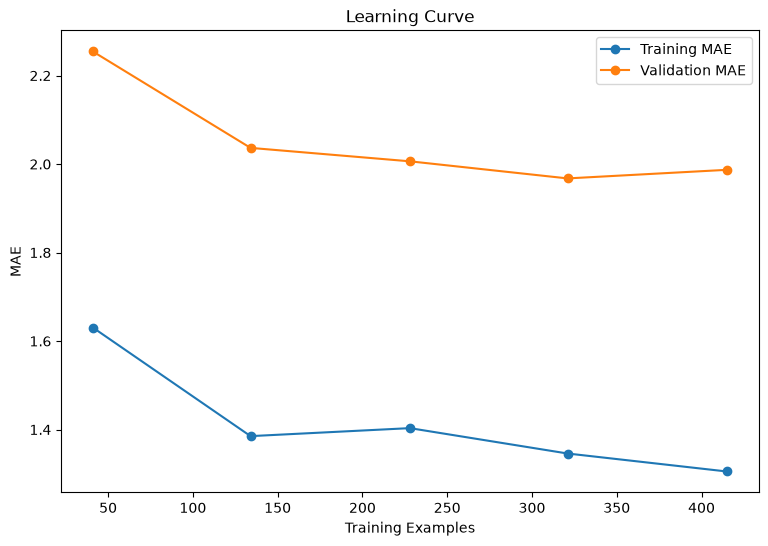

In [12]:
train_sizes, train_scores, validation_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

train_mae = -train_scores.mean(axis=1)

validation_mae = -validation_scores.mean(axis=1)

plt.figure(figsize=(9, 6))

plt.plot(train_sizes, train_mae, marker="o", label="Training MAE")

plt.plot(train_sizes, validation_mae, marker="o", label="Validation MAE")

plt.xlabel("Training Examples")
plt.ylabel("MAE")

plt.title("Learning Curve")

plt.legend()

plt.show()

,Feature,Importance
5,failures,0.290890
12,absences,0.069926
13,school_MS,0.065924
2,Fedu,0.046861
9,Dalc,0.043620
36,higher_yes,0.039106
11,health,0.035865
10,Walc,0.035193
1,Medu,0.033379
4,studytime,0.030394


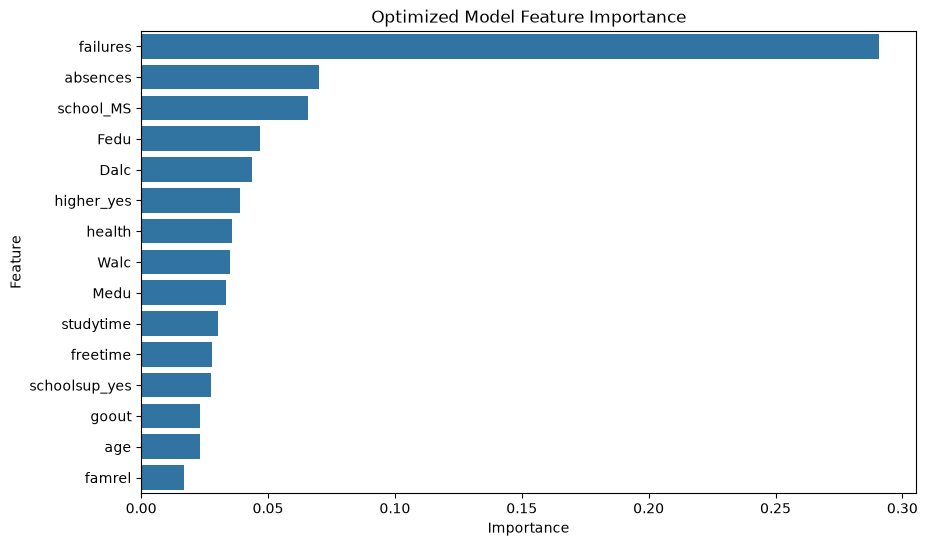

In [13]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance.head(15))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Optimized Model Feature Importance")

plt.show()

In [14]:
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "../models/optimized_student_model.pkl"
)

joblib.dump(
    X.columns.tolist(),
    "../models/model_columns.pkl"
)

print("Optimized model saved successfully!")

Optimized model saved successfully!
